In [2]:
# The predictions of our previous model (in v4_NN) are not good because we take only one character of context

In [3]:
# The size of the count array table N grows exponentially with the length of the context
# If we take single character tp predict the next word like we were doing before, its 27 possibilities for context
# If we take 2 characters as context, it is 27*27 = 729 possibilities for context
# If we take 3 ->> 27*27*27 = 19,683 possibilities for context

# Multi Layer Perceptron Approach by Bengio et al. 2003

In [4]:
# They used vocab_size = 17k and embedding_dim = 30
# The embeddings will be trained during training of the Neural Network.

In [5]:
# You can transfer knowledge through the emdedding space, because once the embeddings are trained they contain similar words in similar part of the embedding space and many different corelations between words that were learned during the training phase of one language model can be used as a starting point for another laguage model.

In [6]:
# C is [17000, 30] #embedding vector


# Building an MLP: From a Bigram Model to a Neural Network

## 1. Objective

- We are taking **three previous words** and trying to predict the **fourth word** in a sequence.
- This is a step up from the bigram model, where we only considered the previous word to predict the next word.
- We now use a neural network to learn patterns from a larger context.

## 2. Input Representation: Word Indices

- We have a vocabulary of **17,000 possible words**.
- Each incoming word is represented by its index in the vocabulary.
- Since there are 17,000 words, each index is an integer between:

$$
0 \text{ and } 16,999
$$

- These indices are used to look up the corresponding word embeddings.

## 3. Embedding Matrix (C)

- There is a lookup table called **C**, which is a matrix of size:

$$
C \in \mathbb{R}^{17000 \times 30}
$$

- We treat this matrix as a lookup table.
- Each word index plucks out a row from the embedding matrix.
- Each row is a 30-dimensional vector corresponding to the embedding of that word.

In other words:

- Input: An integer representing a word's index.
- Output: A 30-dimensional embedding vector.

**Important:** The same embedding matrix C is shared across all three input words. We are always indexing into the same matrix C for each word.

## 4. Input Layer

- Each of the three previous words is converted into a 30-dimensional embedding vector.
- These three embedding vectors are concatenated together.

Therefore, the total number of input neurons is:

$$
3 \times 30 = 90
$$

So, the input layer consists of **90 neurons**.

## 5. Hidden Layer

- Next comes the hidden layer of the neural network.
- The size of this hidden layer is a **hyperparameter**.
- A hyperparameter is essentially a design choice made by the designer of the neural network.
- We can choose this size to be as large or as small as we like.

For example, suppose we choose:

$$
\text{Hidden layer size} = 100
$$

- All 100 neurons are fully connected to the 90 inputs.
- This is called a **fully connected layer**.

After this layer, we apply a `tanh` nonlinearity.

$$
h = \tanh(W_1 x + b_1)
$$

Where:
- $x$ is the 90-dimensional concatenated embedding vector.
- $W_1$ represents the weights connecting the input layer to the hidden layer.
- $b_1$ represents the biases.
- $h$ is the resulting hidden-layer activation.

## 6. Output Layer

- After the hidden layer comes the output layer.
- Since there are 17,000 possible words that could come next, the output layer has **17,000 neurons**.
- Every neuron in the output layer is fully connected to every neuron in the hidden layer.

The output layer produces 17,000 logits:

$$
\text{logits} = W_2 h + b_2
$$

Where:
- $W_2$ represents the weights connecting the hidden layer to the output layer.
- $b_2$ represents the biases.
- Each logit corresponds to one possible word in the vocabulary.

**Important:** This is the expensive layer because there are so many possible words, resulting in a large number of parameters and a significant amount of computation.

## 7. Softmax Layer

- We have 17,000 logits coming out of the output layer.
- We apply the softmax function to convert these logits into a probability distribution.
- Every logit is exponentiated, and then everything is normalized so that the probabilities sum to one.

$$
P(y_i) = \frac{e^{z_i}}{\sum_{j=1}^{17000} e^{z_j}}
$$

Where:
- $z_i$ is the logit corresponding to word $i$.
- $P(y_i)$ is the predicted probability of word $i$ being the next word.

The result is a probability distribution over all 17,000 possible next words.

## 8. Training: Using the Actual Next Word

- During training, we already know the actual next word in the sequence. This is our **label**.
- The identity (index) of that next word is used to pluck out its corresponding probability from the softmax output.
- We then maximize the probability assigned to the correct next word with respect to the parameters of the neural network.

Equivalently, we minimize the negative log probability of the correct word:

$$
L = -\log P(\text{correct next word})
$$

The network learns by adjusting its parameters to increase the probability of the correct next word.

---

## Overall Architecture

The complete flow looks like this:

1. **Three previous words:** Represented by integer indices from 0 to 16,999.
2. **Embedding lookup (C):** Each index retrieves a 30-dimensional embedding vector.
3. **Concatenation:** Three embeddings are concatenated into a 90-dimensional input.
4. **Hidden layer:** A fully connected layer with 100 neurons (example hyperparameter).
5. **Nonlinearity:** Apply `tanh`.
6. **Output layer:** A fully connected layer with 17,000 neurons producing logits.
7. **Softmax:** Convert logits into a probability distribution over the vocabulary.
8. **Training:** Use the actual next word's index to retrieve its probability and maximize that probability.

**Note:** The hidden layer size of 100 and embedding dimension of 30 are example design choices, not fixed requirements.


In [7]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [8]:
words = open('/content/sample_data/names.txt').read().splitlines()

In [9]:
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [10]:
len(words)

32033

In [11]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
print(stoi)
print(itos)

{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26, '.': 0}
{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


**Note:** we are not doing ```.emma.```  and then doing indexing. But instead we are just doing ```emma.```. This is beacuase the `.` at the beginning is being handled by the padded context of `[0,0,0]` that we start with.

The thing gets handled automatically without us having to set is manually

In [12]:
# build the dataset - No, but For real, for real this time

block_size = 3 # context length: how many characters do we take to predit the next character.
X, Y = [], []

for w in words:

    #print(w)
    context = [0]* block_size

    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        # print(''.join(itos[i] for i in context), '--->', itos[ix])
        context = context[1:] + [ix] # Crop and append, this is the main thing being done here. we shift exisitng characters left by 1 and add the newest cahracter to the right. The left most character gets cut off

X = torch.tensor(X)
Y = torch.tensor(Y)

In [13]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [14]:
C = torch.randn((27, 2))

In [15]:
C[5]

tensor([ 1.2596, -0.7231])

In [16]:
F.one_hot(torch.tensor(5), num_classes=27).float() @ C

tensor([ 1.2596, -0.7231])

In [17]:
# indexing from embedding_matrix C is equivalent to onehot matrix multiplication.
# We'll use indexing as its faster.

In [18]:
# Pytorch indexing is very powerful, we can index with a list, or even a tensor of integers

In [19]:
# We can also so 2D tesnor indexing

In [20]:
C[X].shape

torch.Size([228146, 3, 2])

In [21]:
emb = C[X]
emb.shape

torch.Size([228146, 3, 2])

In [22]:
# Let's initalize the Weights of Layer 1 (i,e,layer_10 - from 0 to 1)

# For our example where we have context length = 3 (same as paper), but embedding_dim = 2, the total number of inputs in a[0], ie x is 6.

# So layer 0 has 6 neurons
# Layer 1 has 100 neurons

In [23]:
W1 = torch.randn(6,100)
b1 = torch.randn(100)

In [24]:
# We need to do emb @ W1 + b1
# But emb = [32,3,2] and W1 = [6,100]
# So we need to reshape using view function.
# emb = emb.view(32, 6)
# Then ->>>   emb @ W1 + b1

In [25]:
 # .view() is extemently efficient in PyTroch

In [26]:
h = torch.tanh(emb.view(-1,6) @ W1 + b1)
# When we do -1, Pytoch will infer what this must be
# Then apply the activation function

In [27]:
print((emb.view(-1,6) @ W1).shape)
print(b1.shape)

torch.Size([228146, 100])
torch.Size([100])


In [28]:
W2 = torch.randn((100,27))
b2 = torch.randn(27)

In [29]:
logits = h @ W2 + b2

In [30]:
counts = logits.exp()
prob = counts/ counts.sum(dim=1, keepdims=True)

In [31]:
num_examples = X.shape[0]
prob[torch.arange(num_examples ), Y]

tensor([1.8897e-06, 5.9681e-15, 4.4133e-08,  ..., 7.9284e-05, 9.3368e-12,
        8.9453e-09])

In [32]:
nll = -prob[torch.arange(num_examples ), Y].log().mean()
nll

tensor(15.9685)

In [33]:
# ----------- now more respactable :)------------

In [34]:
X.shape, Y.shape  #dataset

(torch.Size([228146, 3]), torch.Size([228146]))

In [35]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [36]:
for p in parameters:
  p.requires_grad = True

In [38]:
for _ in range(10):

    # forward pass
    emb = C[X] # [m, 3, 2]
    h = torch.tanh(emb.view(-1,6) @ W1 + b1)    # [m, 100]
    logits = h @ W2 + b2                        #[m, 27]
    loss = F.cross_entropy(logits,Y)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    for p in parameters:
        p.data += -0.1 * p.grad

print(loss.item())

5.3585357666015625


In [39]:
# When full batch is used , training is fairly slow


## 9. Training on the Full Dataset

- Previously, we were training on only 32 examples.
- Now we load the **entire dataset**, which gives us approximately **228,000 examples**.
- We initialize the weights with the same number of parameters as before, and all of them require gradients.
- We then run the optimization over the full dataset.

Initially, the loss is fairly high. As we continue optimizing, the loss starts decreasing.

### The Problem: Training on the Entire Dataset Is Slow

- Each iteration requires a forward pass and a backward pass over all 228,000 examples.
- This means we are doing a lot of unnecessary computation for every single optimization step.
- Consequently, each iteration takes quite a bit of time.

To address this, we introduce **mini-batch training**.

## 10. Mini-Batch Gradient Descent

Instead of performing the forward pass, backward pass, and parameter update on the entire dataset, we randomly select a small portion of the dataset.

This small portion is called a **mini-batch**.

The process is:

1. Randomly select a subset of examples from the dataset.
2. Perform the forward pass only on this mini-batch.
3. Calculate the loss.
4. Perform the backward pass.
5. Update the parameters.
6. Repeat with another mini-batch.

This allows us to perform many more optimization steps in less time.

### Implementing Mini-Batch Sampling in PyTorch

We can use `torch.randint()` to randomly generate indices into our dataset.

For example, suppose our mini-batch size is 32:

```python
ix = torch.randint(0, x.shape[0], (32,))
```

Here:
- `x.shape[0]` gives us the total number of examples in the dataset (228,000).
- `(32,)` specifies that we want 32 random indices.
- `ix` contains 32 randomly generated integers that index into our dataset.

We then use these indices to select the corresponding examples:

```python
# Construct a mini-batch
xb = x[ix]
yb = y[ix]
```

Where:
- `xb` contains the 32 selected input examples.
- `yb` contains their corresponding target labels.

We must use the same indices for both `x` and `y` so that every input remains paired with its correct target.

### Difference in Tensor Dimensions

Previously, when processing the entire dataset, the embedding tensor had dimensions:

$$
228000 \times 3 \times 2
$$

With a mini-batch size of 32, we now have:

$$
32 \times 3 \times 2
$$

We are therefore processing only 32 examples instead of 228,000 in each iteration.

This makes the forward and backward passes significantly faster.

## 11. Why Do Mini-Batches Work?

There is an important trade-off when using mini-batches.

- When we calculate gradients using the entire dataset, we get the exact gradient direction for the current model parameters.
- When we calculate gradients using only a mini-batch, we get an estimate of the actual gradient direction.

Because we are using only 32 examples, the gradient direction is less reliable and may differ from the gradient calculated using the entire dataset.

However, the estimated gradient is still useful.

**The key insight:**

It is often much better to calculate an approximate gradient using a small mini-batch and take many optimization steps than to calculate the exact gradient using the entire dataset and take fewer steps.

This is why mini-batch gradient descent works so well in practice.

By using mini-batches:
- Each optimization iteration becomes much faster.
- We can perform many more parameter updates.
- The approximate gradient is generally good enough to guide optimization in the right direction.

We can now continue optimizing the neural network using mini-batches rather than the entire dataset.


In [40]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [41]:
for p in parameters:
  p.requires_grad = True

In [42]:
for k in range(100):

    # minibatch construct
    ix = torch.randint(0, num_examples, (32,))

    # forward pass
    emb = C[X[ix]] # [32, 3, 2]
    h = torch.tanh(emb.view(-1,6) @ W1 + b1)    # [32, 100]
    logits = h @ W2 + b2                        #[32, 27]
    loss = F.cross_entropy(logits,Y[ix])
    if k%10 ==0: print(loss.item())

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    for p in parameters:
        p.data += -0.1 * p.grad



19.27681541442871
10.97438907623291
11.119121551513672
6.959096431732178
5.659989356994629
5.762254238128662
4.449495315551758
3.59307599067688
3.877849817276001
5.076968193054199


In [43]:
# check loss on the complete dataset
emb = C[X] # [m, 3, 2]
h = torch.tanh(emb.view(-1,6) @ W1 + b1)    # [m, 100]
logits = h @ W2 + b2                        #[m, 27]
loss = F.cross_entropy(logits,Y)
loss

tensor(3.8379, grad_fn=<NllLossBackward0>)

In [44]:
# Determining a Reasonable Learning Rate

# Reset to initial parameters
# Only do this precedure for 100 steps.
# Find a reasonable seach range - say 10^-3 to 1

# At low range( 10^-3) the loss should somewhat decrease, but not by much
# For high range, loss kind of unstable.

In [45]:
torch.linspace(0.001, 1, 1000)
# Creates 1000 points between 0.001 and 1
# But it doesn't make sense to stap between them linearly.

# So we use another way
# use -> torch.linsapce(-3, 0, 1000)
# Then raise each of them to a power. How does this step?

# It makes the spacing logarithmic. linspace(-3, 0, 1000) doesn’t produce learning rates. It produces exponents, evenly spaced. Raising 10 to each one turns that even spacing in the exponent into even spacing in orders of magnitude:

lre = torch.linspace(-3, 0, 1000)   # exponents: -3.000, -2.997, ..., 0.000
lrs = 10**lre                        # learning rates: 0.001, ..., 1.0

In [82]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
  p.requires_grad = True

In [83]:
lre = torch.linspace(-3, 0, 1000)   # exponents: -3.000, -2.997, ..., 0.000
lrs = 10**lre                        # learning rates: 0.001, ..., 1.0

In [61]:
# Here we'll use a learning rate that is very very low in the beginning, but by the end its going to be 1.
# Now what we are going to do is keep track of the learning rates that we used and the losses that resulted

In [78]:
lri = []
lossi = []

for i in range(1000):   # Make this 1000

    # minibatch construct
    ix = torch.randint(0, X.shape[0], (32,))

    # forward pass
    emb = C[X[ix]] # [32, 3, 2]
    h = torch.tanh(emb.view(-1,6) @ W1 + b1)    # [32, 100]
    logits = h @ W2 + b2                        #[32, 27]
    loss = F.cross_entropy(logits,Y[ix])
    #if i%10 ==0: print(loss.item())

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = lrs[i]
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    lri.append(lr)
    lossi.append(loss.item())

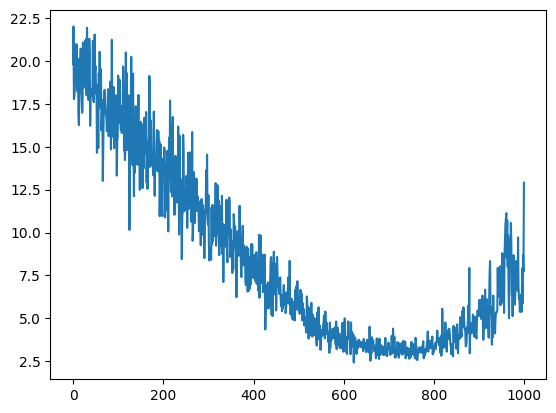

In [79]:
# x-axis ->> iteration number
# y-axis ->> loss
plt.plot(torch.arange(1000), lossi)


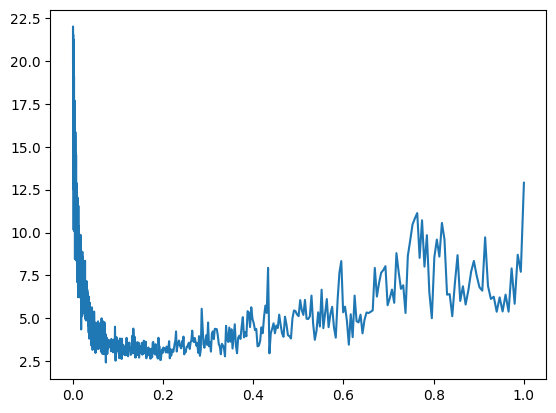

In [80]:
plt.plot(lri, lossi)

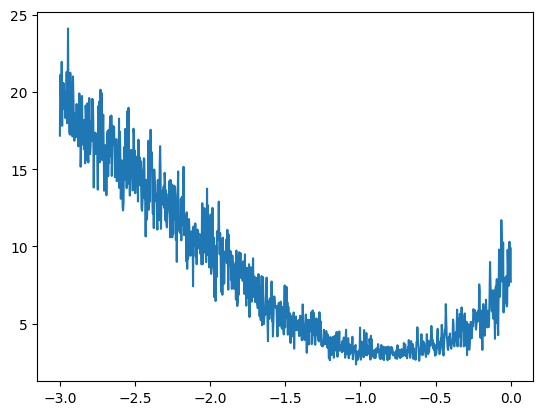

In [84]:
lri = []
lossi = []

for i in range(1000):   # Make this 1000

    # minibatch construct
    ix = torch.randint(0, X.shape[0], (32,))

    # forward pass
    emb = C[X[ix]] # [32, 3, 2]
    h = torch.tanh(emb.view(-1,6) @ W1 + b1)    # [32, 100]
    logits = h @ W2 + b2                        #[32, 27]
    loss = F.cross_entropy(logits,Y[ix])
    #if i%10 ==0: print(loss.item())

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = lrs[i]
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    lri.append(lre[i])  # This is the part that changed from the above loop
    lossi.append(loss.item())

plt.plot(lri, lossi)

In [70]:
lre[50]

tensor(-2.8498)

**Yes, the x-axis is `lre[i]`, not the iteration number, and `lre[50]` is not the log of 50.**

**What `lre[50] = -2.8498` is.** `lre` is just 1000 evenly spaced numbers from $-3$ to $0$:

$$\text{lre}[i] = -3 + \frac{3i}{999} \quad\Rightarrow\quad \text{lre}[50] = -3 + \frac{150}{999} \approx -2.8498$$

So it's the **exponent of the learning rate used at step 50**, not $\log_{10}(50)$, which would be $1.699$. Since `lrs = 10**lre`, we get $\text{lrs}[50] = 10^{-2.8498} \approx 0.00141$. In other words, `lre[i]` is $\log_{10}$ of the learning rate at step $i$.

**Each point is still one training step.** Step $i$ gives the point $(\text{lre}[i],\ \text{loss}_i)$. Because `lre` increases with $i$, left to right is still early to late in training. Only the labels on the x-axis changed. A few steps with their tick labels:

| step $i$ | `lre[i]` | lr $=10^{\text{lre}[i]}$ |
|---|---|---|
| 0 | $-3$ | 0.001 |
| 333 | $-2$ | 0.01 |
| 666 | $-1$ | 0.1 |
| 999 | $0$ | 1.0 |

The tick labels in your second plot read the same way. $-2$ means lr $=0.01$, $-1$ means $0.1$, and $0$ means $1$.

**Why the two plots look so different.** In the first plot the x-axis is the raw lr. If you built `lrs` with the linear `linspace(0.001, 1, 1000)`, then 900 of the 1000 points have lr above 0.1, so the interesting region below 0.1 is squashed into a thin sliver at the left edge. In the second plot each decade, 0.001–0.01, 0.01–0.1 and 0.1–1, gets about a third of the width, and the whole curve is readable. The y-ranges also differ (about 9.6 versus 20+ at the start) because the runs differ. With the log schedule, the first ~330 steps use lr below 0.01, so the loss stays high for a long time.

**Reading the second plot.**
- Left, $e \approx -3$ to $-2$: the loss is high and falling slowly, because the steps are too small.
- Valley, $e \approx -1$ to $-0.7$: the loss is lowest, at lr $\approx 0.1$–$0.2$.
- Right, $e > -0.5$: the loss turns upward and gets noisy, because the steps overshoot.

Pick an lr near the valley bottom, such as $0.1$.

**A bug in your loop:** `if k%10 == 0: print(...)` uses `k`, but your loop variable is `i`. It only runs if `k` is left over from an earlier cell. Change it to `i`.

Where I’d stay cautious. The bias doesn’t clearly go in the direction you describe. Early training is often the least tolerant of big steps. At init the loss here is about 22, far above the ideal $\ln 27 \approx 3.3$, so the gradients are large and the model is in a bad region.

## This is why large networks use lr warmup.
A big lr at step 0 might make the loss drop faster, or it might blow up. For this little MLP I can’t say without testing, and neither can the sweep.

In [87]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
  p.requires_grad = True

In [92]:
for i in range(10000):   # Make this 10000

    # minibatch construct
    ix = torch.randint(0, X.shape[0], (32,))

    # forward pass
    emb = C[X[ix]] # [32, 3, 2]
    h = torch.tanh(emb.view(-1,6) @ W1 + b1)    # [32, 100]
    logits = h @ W2 + b2                        #[32, 27]
    loss = F.cross_entropy(logits,Y[ix])
    #if i%10 ==0: print(loss.item())

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # # track stats
    # lri.append(lre[i])  # This is the part that changed from the above loop
    # lossi.append(loss.item())

In [85]:
# Train with lr = 0.1 till it reaches a good enough point. Then train with 0.01 to see if loss can be further decreased

In [93]:
# check loss on the complete dataset
emb = C[X] # [m, 3, 2]
h = torch.tanh(emb.view(-1,6) @ W1 + b1)    # [m, 100]
logits = h @ W2 + b2                        #[m, 27]
loss = F.cross_entropy(logits,Y)
loss

tensor(2.3605, grad_fn=<NllLossBackward0>)

In [ ]:
# We getting 2.36 as loss, lower than count array loss of 2.47